In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import shap
import joblib
from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

BASE_DIR = Path(r"C:\Projects\cancer-classifier")
PROC_DIR = BASE_DIR / "data" / "processed"
FIG_DIR  = BASE_DIR / "outputs" / "figures"
MOD_DIR  = BASE_DIR / "outputs" / "models"

# Load data
df    = pd.read_parquet(PROC_DIR / "dataset_scaled.parquet")
genes = pd.read_csv(PROC_DIR / "selected_genes.csv").iloc[:, 0].tolist()
df["cancer_type"] = df["cancer_type"].replace("GBM", "LGG")

X = df[genes].values
y = df["cancer_type"].values

# Load saved models
xgb_model = joblib.load(MOD_DIR / "xgboost.joblib")
le        = joblib.load(MOD_DIR / "label_encoder.joblib")
classes   = le.classes_

# Recreate the same train/test split as Step 5
y_enc = le.transform(y)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, random_state=42, stratify=y_enc
)

# Wrap in DataFrame so SHAP knows gene names
X_test_df  = pd.DataFrame(X_test,  columns=genes)
X_train_df = pd.DataFrame(X_train, columns=genes)

print(f"Test set: {X_test_df.shape}")
print(f"Classes : {classes}")


Test set: (159, 340)
Classes : ['BRCA' 'COAD' 'KIRC' 'LGG' 'LUAD']
✅ Everything loaded!


In [5]:
# TreeExplainer is specifically optimized for tree-based models like XGBoost
# It computes exact SHAP values (not approximations) using the tree structure


explainer   = shap.TreeExplainer(xgb_model)
shap_raw    = explainer.shap_values(X_test_df)

# Handle both old (list of 2D) and new (single 3D array) SHAP formats
sv = np.array(shap_raw)
print(f"Raw SHAP array shape: {sv.shape}")

if sv.ndim == 3 and sv.shape[0] == len(classes):
    # Old format: (n_classes, n_samples, n_genes) → keep as-is
    shap_values = [sv[i] for i in range(len(classes))]
    print("Format: old (n_classes, n_samples, n_genes)")
elif sv.ndim == 3 and sv.shape[2] == len(classes):
    # New format: (n_samples, n_genes, n_classes) → transpose
    shap_values = [sv[:, :, i] for i in range(len(classes))]
    print("Format: new (n_samples, n_genes, n_classes)")
elif sv.ndim == 2:
    # Binary classification fallback
    shap_values = [sv, -sv]
    print("Format: binary 2D")
else:
    raise ValueError(f"Unexpected SHAP shape: {sv.shape}")

# Verify shapes match
print(f"\nVerification:")
print(f"  X_test_df shape    : {X_test_df.shape}")
print(f"  shap_values[0] shape: {shap_values[0].shape}")
assert shap_values[0].shape == X_test_df.shape, "Shape mismatch — check output above"
print(f"\n SHAP values ready — {len(shap_values)} classes × {shap_values[0].shape}")

Raw SHAP array shape: (159, 340, 5)
Format: new (n_samples, n_genes, n_classes)

Verification:
  X_test_df shape    : (159, 340)
  shap_values[0] shape: (159, 340)

✅ SHAP values ready — 5 classes × (159, 340)


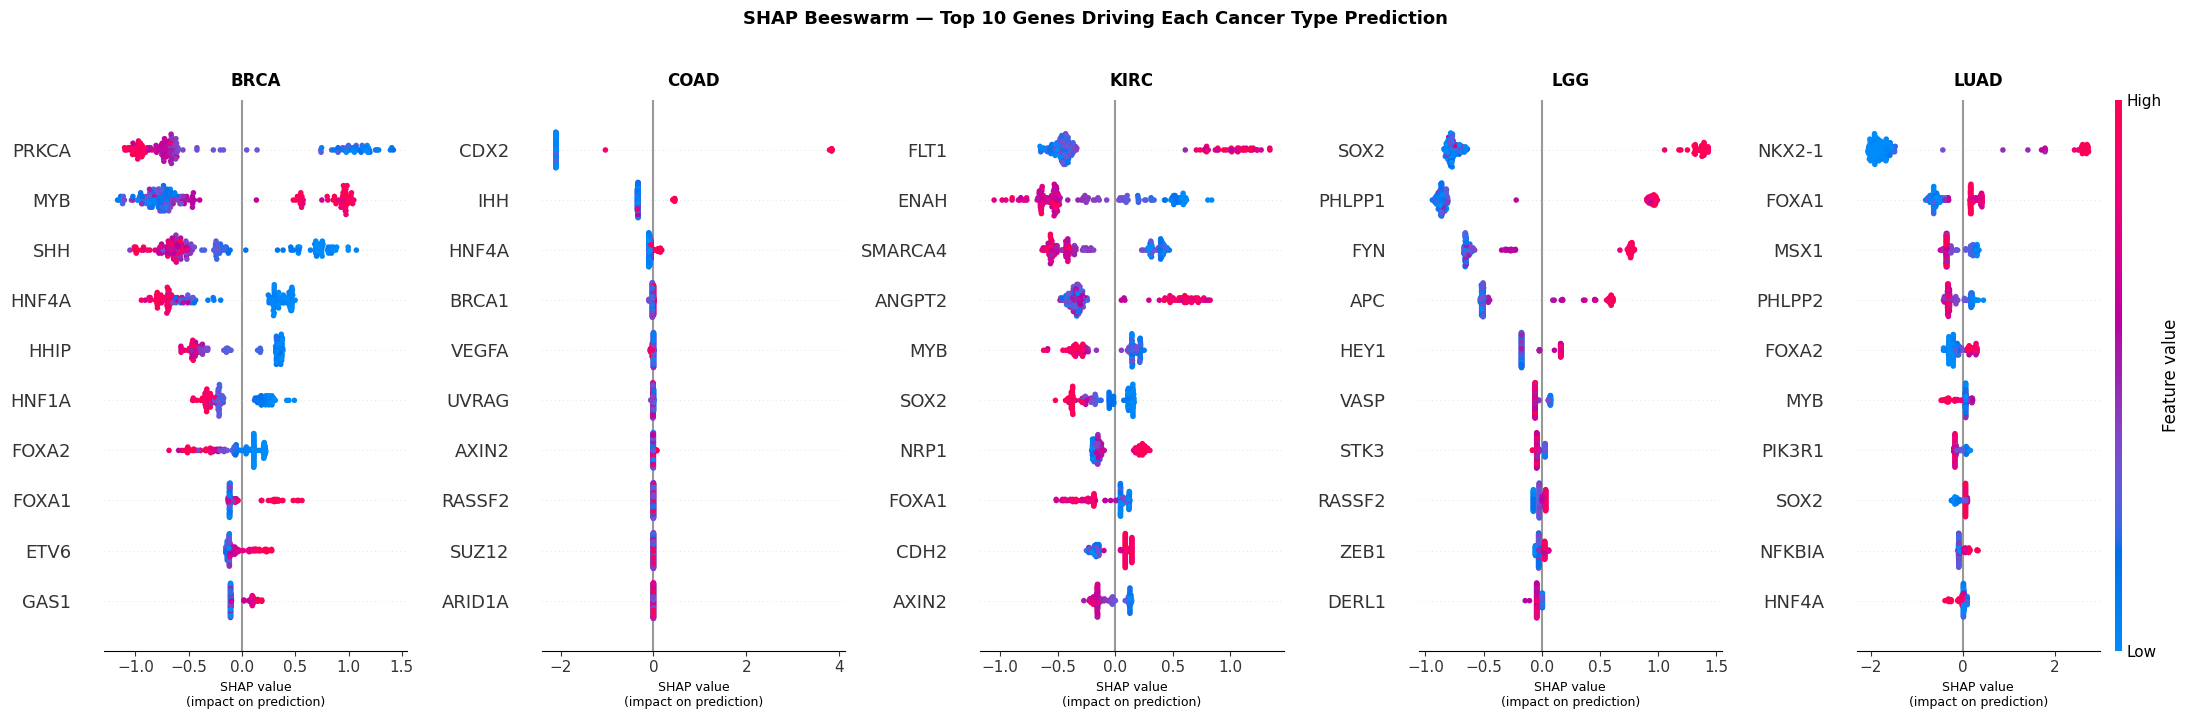

In [6]:
# The beeswarm shows every sample as a dot for every gene
# X-axis = SHAP value (impact on prediction)
# Color  = actual gene expression level (red=high, blue=low)
# This reveals: "high expression of gene X strongly pushes toward cancer Y"

fig, axes = plt.subplots(1, len(classes), figsize=(22, 7))

for i, cancer in enumerate(classes):
    plt.sca(axes[i])
    shap.summary_plot(
        shap_values[i],
        X_test_df,
        max_display=10,        # show top 10 genes
        show=False,
        plot_size=None,
        color_bar=(i == len(classes)-1)  # only show colorbar on last plot
    )
    axes[i].set_title(f"{cancer}", fontsize=12, fontweight="bold", pad=10)
    axes[i].set_xlabel("SHAP value\n(impact on prediction)", fontsize=9)
    if i > 0:
        axes[i].set_ylabel("")

plt.suptitle("SHAP Beeswarm — Top 10 Genes Driving Each Cancer Type Prediction",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()


In [4]:
sv = np.array(shap_values)
print("Raw shap_values type :", type(shap_values))
print("Raw shap_values shape:", sv.shape)
print("X_test_df shape      :", X_test_df.shape)

Raw shap_values type : <class 'numpy.ndarray'>
Raw shap_values shape: (159, 340, 5)
X_test_df shape      : (159, 340)


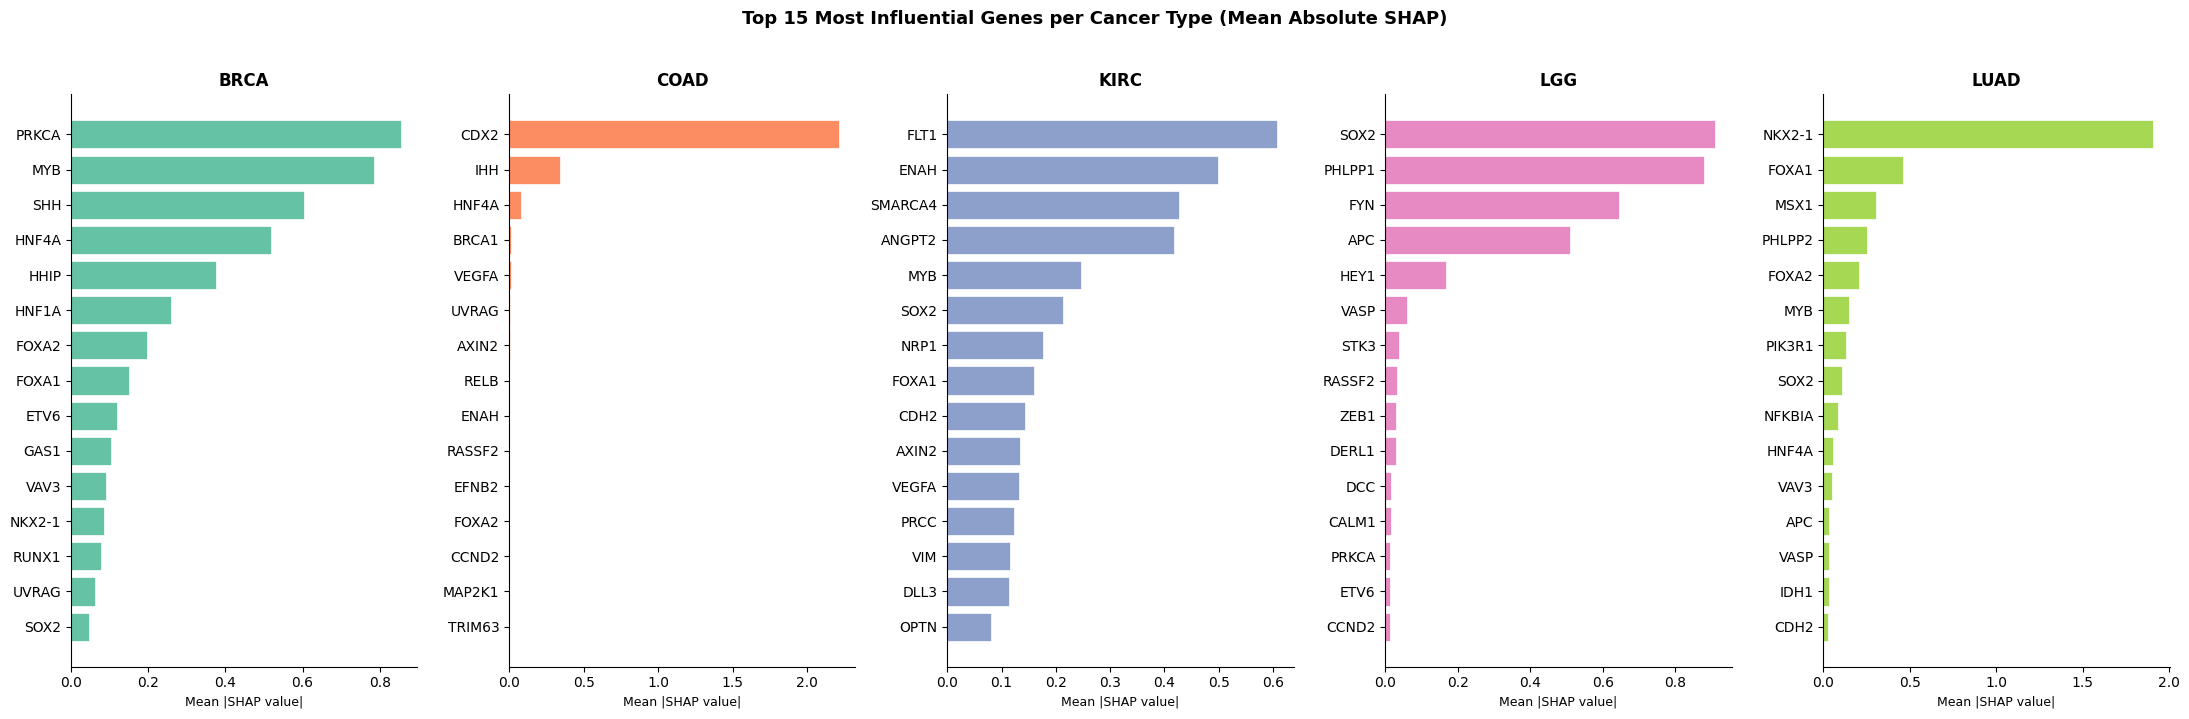

✅ Bar plot saved!


In [7]:
# Mean absolute SHAP value = average impact of each gene across all samples
# This is the most interpretable measure of "which genes matter most"

fig, axes = plt.subplots(1, len(classes), figsize=(22, 7))
PALETTE   = dict(zip(classes, sns.color_palette("Set2", len(classes))))

for i, cancer in enumerate(classes):
    # Mean absolute SHAP across all test samples for this cancer type
    mean_shap = pd.Series(
        np.abs(shap_values[i]).mean(axis=0),
        index=genes
    ).nlargest(15)

    axes[i].barh(
        mean_shap.index[::-1],
        mean_shap.values[::-1],
        color=PALETTE[cancer],
        edgecolor="white",
        linewidth=0.5
    )
    axes[i].set_title(f"{cancer}", fontsize=12, fontweight="bold")
    axes[i].set_xlabel("Mean |SHAP value|", fontsize=9)
    axes[i].spines[["top", "right"]].set_visible(False)
    if i > 0:
        axes[i].set_ylabel("")

plt.suptitle("Top 15 Most Influential Genes per Cancer Type (Mean Absolute SHAP)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "09_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()


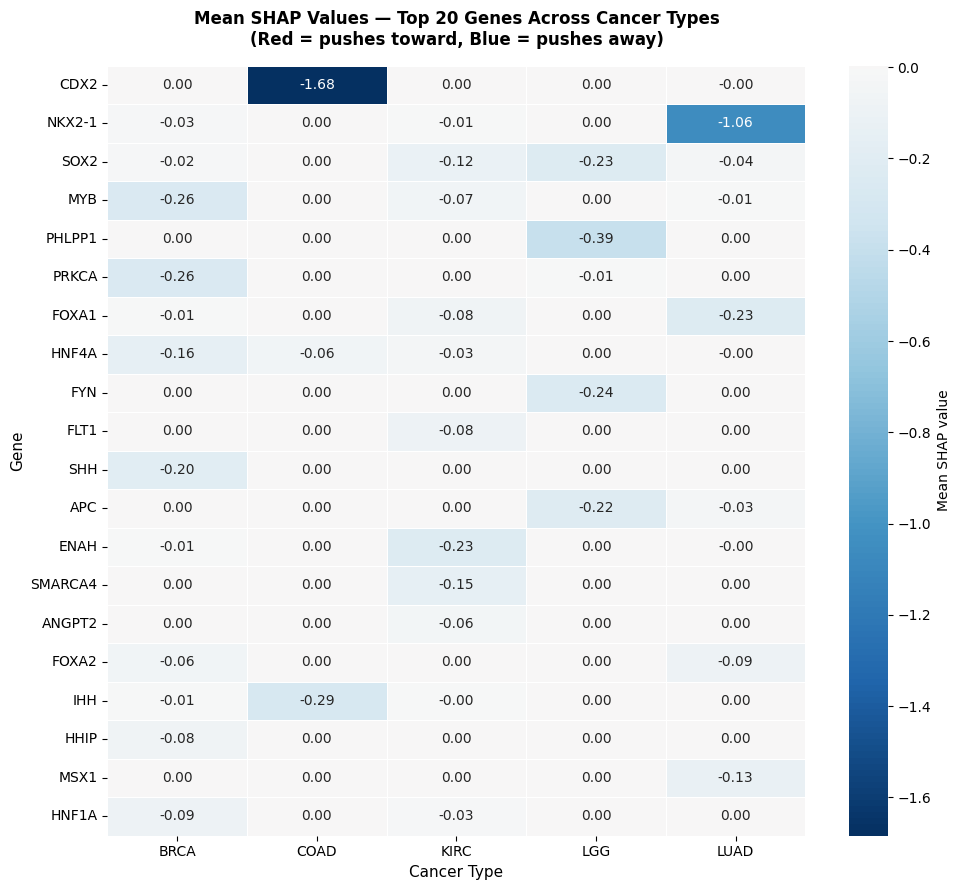

In [8]:
# This shows the top genes globally and their SHAP impact per cancer type
# It reveals which genes are specific to one cancer vs shared across multiple

# Get top 20 globally important genes
global_importance = pd.Series(
    np.abs(np.array(shap_values)).mean(axis=(0, 1)),
    index=genes
).nlargest(20)

top20_genes = global_importance.index.tolist()

# Build matrix: mean SHAP per cancer type for top 20 genes
shap_matrix = pd.DataFrame(
    {cancer: np.array(shap_values[i])[:, [genes.index(g) for g in top20_genes]].mean(axis=0)
     for i, cancer in enumerate(classes)},
    index=top20_genes
)

fig, ax = plt.subplots(figsize=(10, 9))
sns.heatmap(
    shap_matrix,
    cmap="RdBu_r",
    center=0,
    annot=True, fmt=".2f",
    linewidths=0.5,
    ax=ax,
    cbar_kws={"label": "Mean SHAP value"}
)
ax.set_title("Mean SHAP Values — Top 20 Genes Across Cancer Types\n"
             "(Red = pushes toward, Blue = pushes away)",
             fontsize=12, fontweight="bold", pad=15)
ax.set_xlabel("Cancer Type", fontsize=11)
ax.set_ylabel("Gene", fontsize=11)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(FIG_DIR / "10_shap_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()


Sample index : 34
True label   : LUAD
Predicted    : LUAD


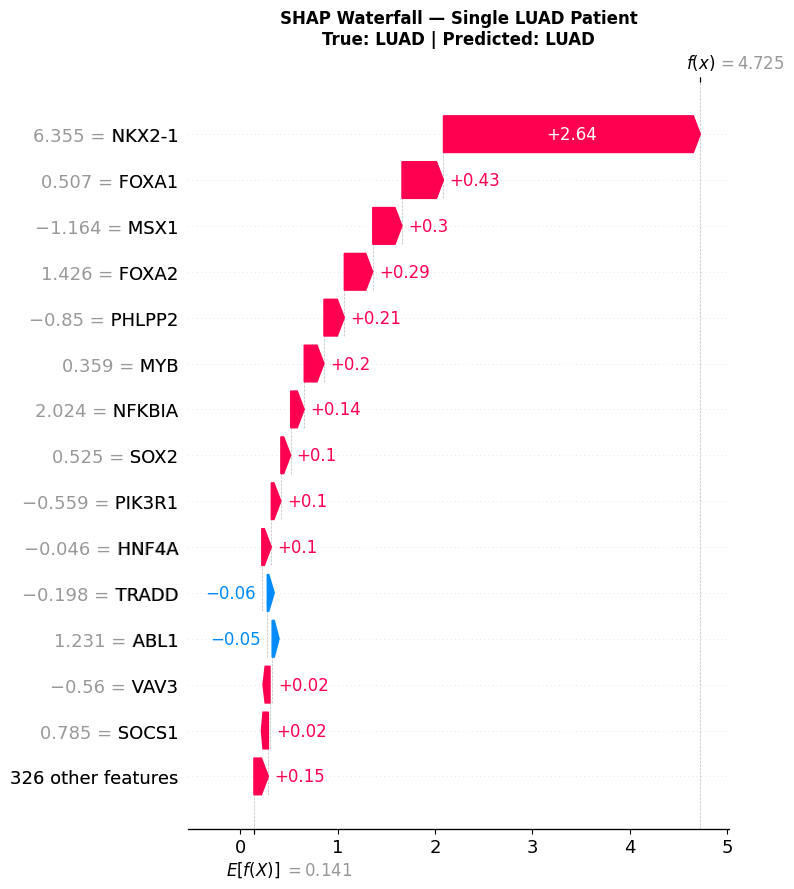

In [9]:
# We will pick one LUAD patient and explain their prediction gene by gene

# Find a correctly predicted LUAD sample
luad_idx  = np.where(y_test == le.transform(["LUAD"])[0])[0][0]
sample    = X_test_df.iloc[[luad_idx]]
pred      = classes[xgb_model.predict(sample)[0]]
true      = classes[y_test[luad_idx]]

print(f"Sample index : {luad_idx}")
print(f"True label   : {true}")
print(f"Predicted    : {pred}")

# SHAP waterfall for the LUAD class
luad_class_idx = list(classes).index("LUAD")

explanation = shap.Explanation(
    values          = shap_values[luad_class_idx][luad_idx],
    base_values     = explainer.expected_value[luad_class_idx],
    data            = X_test_df.iloc[luad_idx].values,
    feature_names   = genes
)

fig = plt.figure(figsize=(10, 8))
shap.waterfall_plot(explanation, max_display=15, show=False)
plt.title(f"SHAP Waterfall — Single LUAD Patient\n"
          f"True: {true} | Predicted: {pred}",
          fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "11_shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()
